In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

print(tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
!ls /content/drive/MyDrive/archive.zip

/content/drive/MyDrive/archive.zip


In [12]:
!unzip -q /content/drive/MyDrive/archive.zip -d /content/smile_data
!find /content/smile_data -maxdepth 3 -type d

/content/smile_data
/content/smile_data/smile
/content/smile_data/test
/content/smile_data/non_smile


In [13]:
!ls /content/smile_data/test | head
!echo "smile:" && ls /content/smile_data/smile | wc -l
!echo "non_smile:" && ls /content/smile_data/non_smile | wc -l
!echo "test:" && ls /content/smile_data/test | wc -l

Aaron_Guiel_0001.jpg
Aaron_Peirsol_0001.jpg
Aaron_Peirsol_0002.jpg
Aaron_Peirsol_0003.jpg
Aaron_Peirsol_0004.jpg
Aaron_Pena_0001.jpg
Aaron_Sorkin_0001.jpg
Aaron_Sorkin_0002.jpg
Aaron_Tippin_0001.jpg
Abba_Eban_0001.jpg
smile:
600
non_smile:
603
test:
12030


In [15]:
!unzip -tq /content/drive/MyDrive/archive.zip

No errors detected in compressed data of /content/drive/MyDrive/archive.zip.


In [20]:
IMG_SIZE = (227, 227)

train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["non_smile", "smile"],
    validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=32)

val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, class_names=["non_smile", "smile"],
    validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=32)


Found 1203 files belonging to 2 classes.
Using 963 files for training.
Found 1203 files belonging to 2 classes.
Using 240 files for validation.


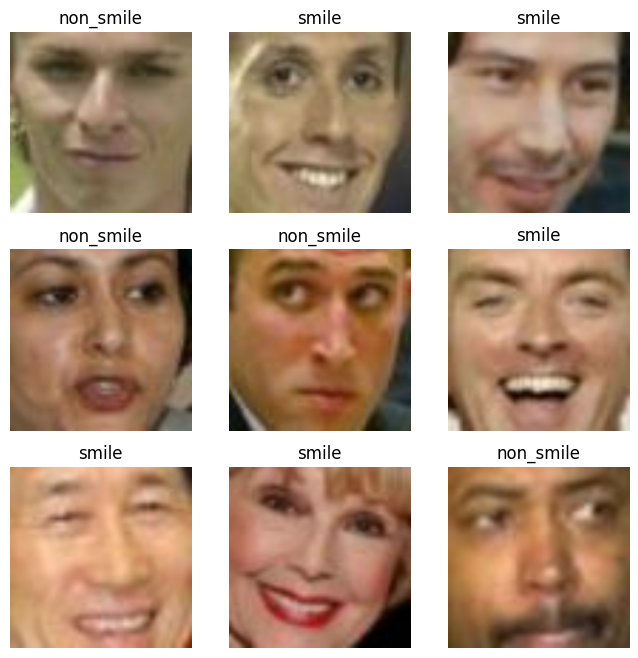

In [21]:
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

In [22]:
alexnet = keras.Sequential([
    layers.Input(shape=(227, 227, 3)),

    # light augmentation + scaling
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Rescaling(1./255),

    # Conv 1
    layers.Conv2D(96, 11, strides=4, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=3, strides=2),

    # Conv 2
    layers.Conv2D(256, 5, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=3, strides=2),

    # Conv 3, 4, 5
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(384, 3, padding="same", activation="relu"),
    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=3, strides=2),

    # Fully connected layers
    layers.Flatten(),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(4096, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])

alexnet.compile(optimizer=keras.optimizers.Adam(1e-4),
                loss="binary_crossentropy",
                metrics=["accuracy"])
alexnet.summary()

history_alex = alexnet.fit(train_ds, validation_data=val_ds, epochs=30)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 227, 227, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 227, 227, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 227, 227, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 55, 55, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 27, 27, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,286,849 (222.35 MB)

 Trainable params: 58,286,145 (222.34 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 134ms/step - accuracy: 0.6584 - loss: 0.7072 - val_accuracy: 0.4625 - val_loss: 0.6917
Epoch 2/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.8442 - loss: 0.3685 - val_accuracy: 0.4583 - val_loss: 0.7095
Epoch 3/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step - accuracy: 0.9252 - loss: 0.2253 - val_accuracy: 0.4583 - val_loss: 0.7897
Epoch 4/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.9242 - loss: 0.2147 - val_accuracy: 0.4583 - val_loss: 1.6280
Epoch 5/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.9398 - loss: 0.1614 - val_accuracy: 0.4583 - val_loss: 2.7195
Epoch 6/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 92ms/step - accuracy: 0.9450 - loss: 0.1481 - val_accuracy: 0.4583 - val_loss: 1.5737
Epoch 7/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - accuracy: 0.9574 - loss: 0.1091 - val_accuracy: 0.4583 - val_loss: 1.8165
Epoch 8/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - accuracy: 0.9315 - loss: 0.1988 - val_accuracy: 0.4583 -

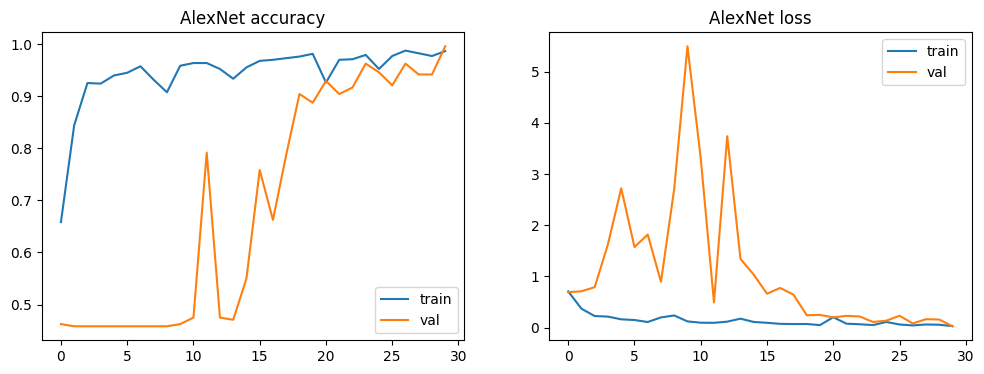

[[110   0]
 [  1 129]]
              precision    recall  f1-score   support

   non_smile       0.99      1.00      1.00       110
       smile       1.00      0.99      1.00       130

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



In [23]:
# 1. Training curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_alex.history["accuracy"], label="train")
plt.plot(history_alex.history["val_accuracy"], label="val")
plt.title("AlexNet accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_alex.history["loss"], label="train")
plt.plot(history_alex.history["val_loss"], label="val")
plt.title("AlexNet loss"); plt.legend()
plt.show()

# 2. Confusion matrix and per-class scores
from sklearn.metrics import classification_report, confusion_matrix
y_true, y_pred = [], []
for images, labels in val_ds:
    probs = alexnet.predict(images, verbose=0).ravel()
    y_pred.extend((probs > 0.5).astype(int))
    y_true.extend(labels.numpy())
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["non_smile", "smile"]))

In [24]:
alexnet.save("/content/drive/MyDrive/smile_alexnet.keras")

Saving Anneli_Jaatteenmaki_0001.jpg to Anneli_Jaatteenmaki_0001.jpg


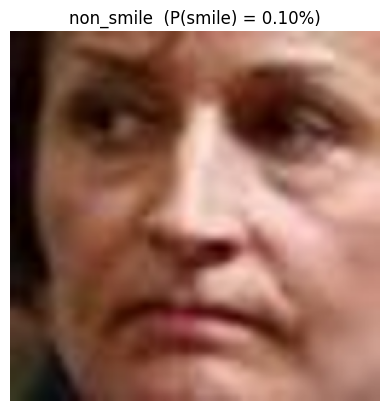

In [28]:
from google.colab import files
from PIL import Image

uploaded = files.upload()                 # pick this one image
path = list(uploaded.keys())[0]

img = Image.open(path).convert("RGB").resize((227, 227))
x = np.expand_dims(np.array(img, dtype="float32"), 0)   # model rescales internally

p = float(alexnet.predict(x, verbose=0)[0][0])          # probability of "smile"
label = "smile" if p > 0.5 else "non_smile"

plt.imshow(img)
plt.title(f"{label}  (P(smile) = {p:.2%})")
plt.axis("off")
plt.show()